<a href="https://colab.research.google.com/github/Sourabh-IISER/LEAF_CLASSIFICATION/blob/main/notebooks/leaf_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **DATA LOADING AND IMAGE PROCESSING ~ Sourabh **

In [ ]:
!pip install -q opencv-python scikit-image scikit-learn pandas matplotlib seaborn pillow

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

from skimage.feature import graycomatrix, graycoprops

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported.")

All libraries imported.


In [ ]:
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

OpenCV version: 4.14.0
NumPy version: 2.1.3
Pandas version: 2.2.3


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/Leaf_Classification/Dataset/archive.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    files = zip_ref.namelist()

print("Total files in ZIP:", len(files))

print("\nFirst 50 files/folders:")
for item in files[:50]:
    print(item)

Total files in ZIP: 4502

First 50 files/folders:
Plants_2/images to predict/0001_0170.JPG
Plants_2/images to predict/0003_0179.JPG
Plants_2/images to predict/0005_0268.JPG
Plants_2/images to predict/0008_0148.JPG
Plants_2/images to predict/0015_0123.JPG
Plants_2/images to predict/0016_0118.JPG
Plants_2/images to predict/0019_0276.JPG
Plants_2/images to predict/0020_0271.JPG
Plants_2/test/Alstonia Scholaris diseased (P2a)/0014_0006.JPG
Plants_2/test/Alstonia Scholaris diseased (P2a)/0014_0007.JPG
Plants_2/test/Alstonia Scholaris diseased (P2a)/0014_0008.JPG
Plants_2/test/Alstonia Scholaris diseased (P2a)/0014_0009.JPG
Plants_2/test/Alstonia Scholaris diseased (P2a)/0014_0010.JPG
Plants_2/test/Alstonia Scholaris healthy (P2b)/0003_0006.JPG
Plants_2/test/Alstonia Scholaris healthy (P2b)/0003_0007.JPG
Plants_2/test/Alstonia Scholaris healthy (P2b)/0003_0008.JPG
Plants_2/test/Alstonia Scholaris healthy (P2b)/0003_0009.JPG
Plants_2/test/Alstonia Scholaris healthy (P2b)/0003_0010.JPG
Plants_

In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/Leaf_Classification/Dataset/archive.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    all_files = zip_ref.namelist()

# Find folders immediately inside Plants_2/test/
test_classes = set()

for file_path in all_files:
    parts = file_path.split("/")

    if len(parts) >= 3 and parts[0] == "Plants_2" and parts[1] == "test":
        test_classes.add(parts[2])

print("Classes found in test folder:")
for class_name in sorted(test_classes):
    print(class_name)

print("\nNumber of classes:", len(test_classes))

Classes found in test folder:
Alstonia Scholaris diseased (P2a)
Alstonia Scholaris healthy (P2b)
Arjun diseased (P1a)
Arjun healthy (P1b)
Bael diseased (P4b)
Basil healthy (P8)
Chinar diseased (P11b)
Chinar healthy (P11a)
Gauva diseased (P3b)
Gauva healthy (P3a)
Jamun diseased (P5b)
Jamun healthy (P5a)
Jatropha diseased (P6b)
Jatropha healthy (P6a)
Lemon diseased (P10b)
Lemon healthy (P10a)
Mango diseased (P0b)
Mango healthy (P0a)
Pomegranate diseased (P9b)
Pomegranate healthy (P9a)
Pongamia Pinnata diseased (P7b)
Pongamia Pinnata healthy (P7a)

Number of classes: 22


In [ ]:
train_classes = set()

for file_path in all_files:
    parts = file_path.split("/")

    if len(parts) >= 3 and parts[0] == "Plants_2" and parts[1] == "train":
        train_classes.add(parts[2])

print("Classes found in train folder:")
for class_name in sorted(train_classes):
    print(class_name)

print("\nNumber of classes:", len(train_classes))

Classes found in train folder:
Alstonia Scholaris diseased (P2a)
Alstonia Scholaris healthy (P2b)
Arjun diseased (P1a)
Arjun healthy (P1b)
Bael diseased (P4b)
Basil healthy (P8)
Chinar diseased (P11b)
Chinar healthy (P11a)
Gauva diseased (P3b)
Gauva healthy (P3a)
Jamun diseased (P5b)
Jamun healthy (P5a)
Jatropha diseased (P6b)
Jatropha healthy (P6a)
Lemon diseased (P10b)
Lemon healthy (P10a)
Mango diseased (P0b)
Mango healthy (P0a)
Pomegranate diseased (P9b)
Pomegranate healthy (P9a)
Pongamia Pinnata diseased (P7b)
Pongamia Pinnata healthy (P7a)

Number of classes: 22


In [ ]:
import os

project_dataset_path = "/content/drive/MyDrive/Leaf_Classification/Dataset/images"

species = [
    "Mango",
    "Gauva",
    "Jamun",
    "Lemon",
    "Pomegranate"
]

for species_name in species:
    os.makedirs(
        os.path.join(project_dataset_path, species_name),
        exist_ok=True
    )

print("Project dataset folders created.")

for species_name in species:
    print(species_name)

Project dataset folders created.
Mango
Gauva
Jamun
Lemon
Pomegranate


In [ ]:
import zipfile
import os
import shutil

zip_path = "/content/drive/MyDrive/Leaf_Classification/Dataset/archive.zip"

# Final class name : original Kaggle folder names
class_mapping = {
    "Mango": [
        "Mango healthy (P0a)",
        "Mango diseased (P0b)"
    ],
    "Guava": [
        "Gauva healthy (P3a)",
        "Gauva diseased (P3b)"
    ],
    "Jamun": [
        "Jamun healthy (P5a)",
        "Jamun diseased (P5b)"
    ],
    "Lemon": [
        "Lemon healthy (P10a)",
        "Lemon diseased (P10b)"
    ],
    "Pomegranate": [
        "Pomegranate healthy (P9a)",
        "Pomegranate diseased (P9b)"
    ]
}

# Create separate train and test folders
for split in ["train", "test"]:
    for class_name in class_mapping:
        folder_path = os.path.join(
            project_dataset_path,
            split,
            class_name
        )
        os.makedirs(folder_path, exist_ok=True)

# Extract images
with zipfile.ZipFile(zip_path, "r") as zip_ref:

    all_files = zip_ref.namelist()

    for split in ["train", "test"]:

        for final_class, original_classes in class_mapping.items():

            output_folder = os.path.join(
                project_dataset_path,
                split,
                final_class
            )

            for original_class in original_classes:

                prefix = f"Plants_2/{split}/{original_class}/"

                for file_path in all_files:

                    if (
                        file_path.startswith(prefix)
                        and file_path.lower().endswith(
                            (".jpg", ".jpeg", ".png", ".bmp")
                        )
                    ):

                        file_name = os.path.basename(file_path)

                        # Prevent duplicate filenames
                        new_file_name = (
                            f"{original_class.replace(' ', '_')}_{file_name}"
                        )

                        output_path = os.path.join(
                            output_folder,
                            new_file_name
                        )

                        with zip_ref.open(file_path) as source:
                            with open(output_path, "wb") as target:
                                shutil.copyfileobj(source, target)

print("Extraction completed successfully!")

Extraction completed successfully!


In [ ]:
for split in ["train", "test"]:

    print(f"\n_________ {split.upper()} _________")

    for class_name in ["Mango", "Guava", "Jamun", "Lemon", "Pomegranate"]:

        folder = os.path.join(
            project_dataset_path,
            split,
            class_name
        )

        image_files = [
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
        ]

        print(f"{class_name}: {len(image_files)} images")


_________ TRAIN _________
Mango: 414 images
Guava: 398 images
Jamun: 603 images
Lemon: 216 images
Pomegranate: 538 images

_________ TEST _________
Mango: 10 images
Guava: 10 images
Jamun: 10 images
Lemon: 10 images
Pomegranate: 10 images


In [ ]:
import cv2
import os
import numpy as np

image_sizes = []

for split in ["train", "test"]:
    for class_name in ["Mango", "Guava", "Jamun", "Lemon", "Pomegranate"]:

        folder = os.path.join(
            project_dataset_path,
            split,
            class_name
        )

        for file_name in os.listdir(folder):

            if file_name.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):

                image_path = os.path.join(folder, file_name)

                image = cv2.imread(image_path)

                if image is not None:
                    height, width = image.shape[:2]
                    image_sizes.append((width, height))

print("Total images checked:", len(image_sizes))

widths = [size[0] for size in image_sizes]
heights = [size[1] for size in image_sizes]

print("Minimum width:", min(widths))
print("Maximum width:", max(widths))
print("Minimum height:", min(heights))
print("Maximum height:", max(heights))

print("\nMost common image size:")

from collections import Counter

size_counts = Counter(image_sizes)

for size, count in size_counts.most_common(10):
    print(size, ":", count, "images")

Total images checked: 2219
Minimum width: 6000
Maximum width: 6000
Minimum height: 4000
Maximum height: 4000

Most common image size:
(6000, 4000) : 2219 images


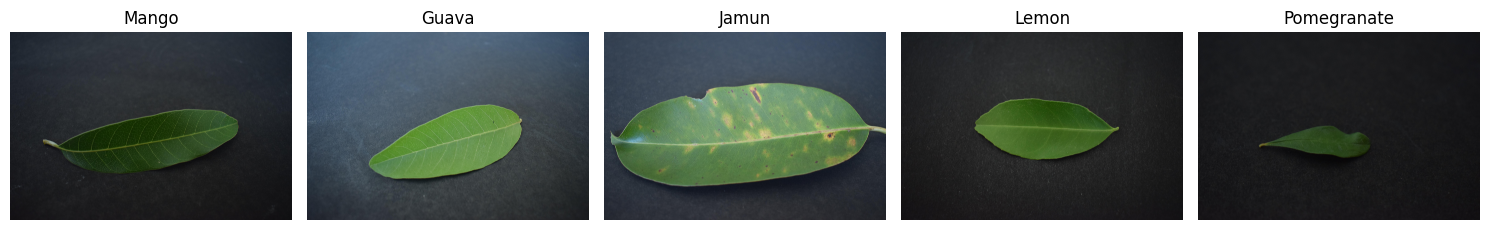

In [ ]:
import matplotlib.pyplot as plt
import cv2
import os
import random

classes = ["Mango", "Guava", "Jamun", "Lemon", "Pomegranate"]

plt.figure(figsize=(15, 10))

plot_number = 1

for class_name in classes:

    folder = os.path.join(
        project_dataset_path,
        "train",
        class_name
    )

    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    selected_image = random.choice(image_files)

    image_path = os.path.join(folder, selected_image)

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(1, 5, plot_number)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

    plot_number += 1

plt.tight_layout()
plt.show()

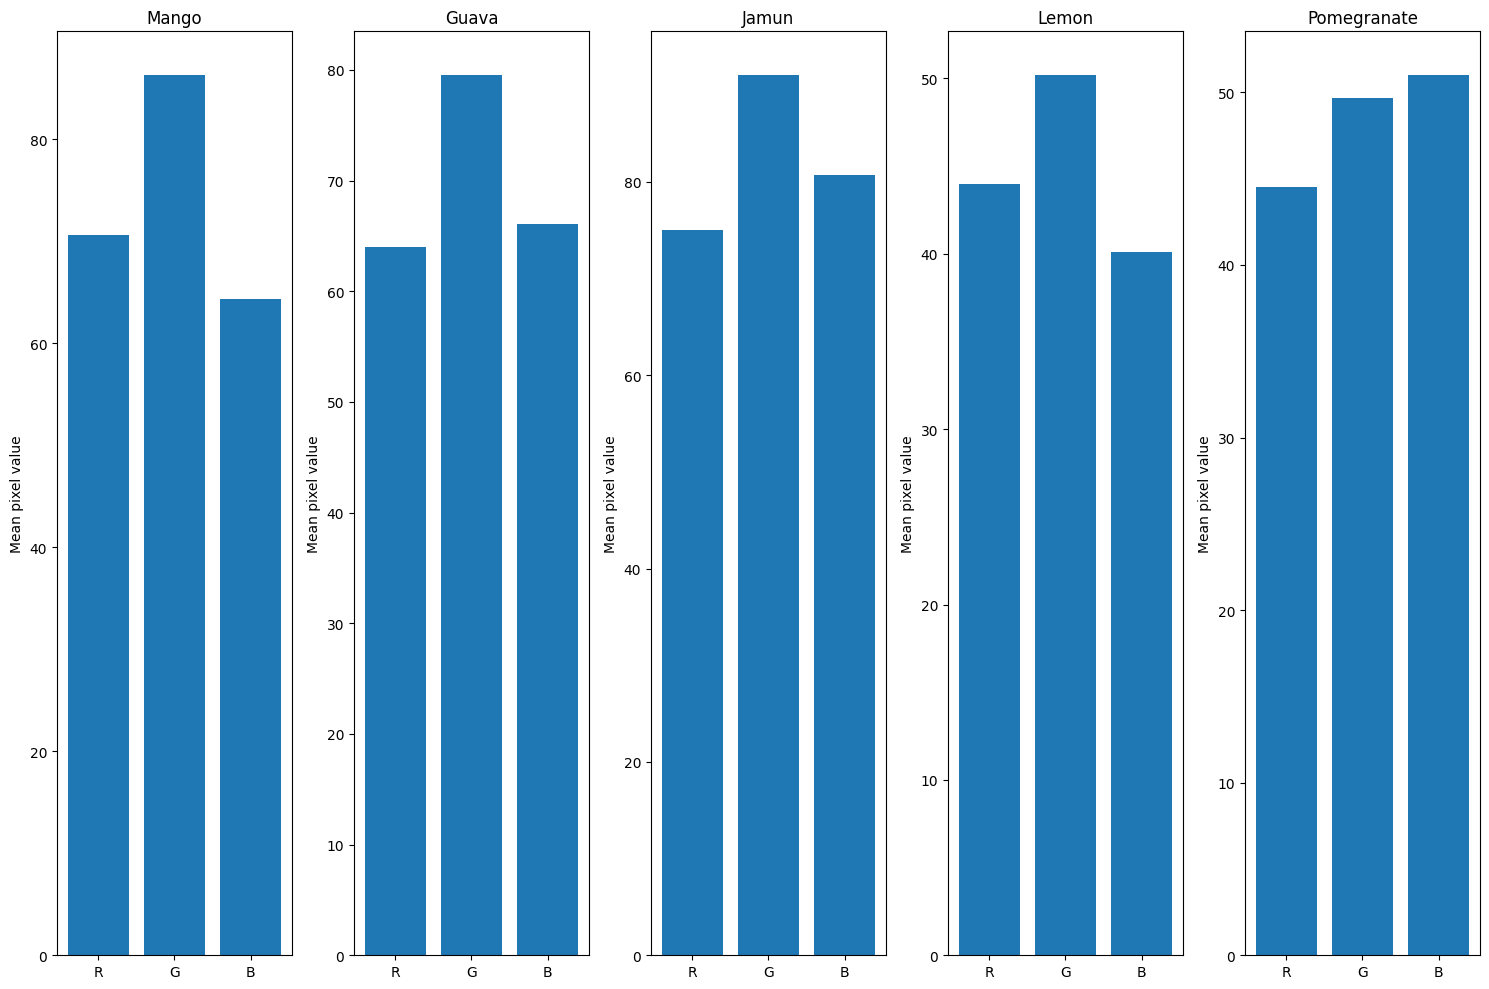

In [ ]:
import matplotlib.pyplot as plt
import cv2
import os
import random
import numpy as np

classes = ["Mango", "Guava", "Jamun", "Lemon", "Pomegranate"]

plt.figure(figsize=(15, 10))

plot_number = 1

for class_name in classes:

    folder = os.path.join(
        project_dataset_path,
        "train",
        class_name
    )

    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    selected_image = random.choice(image_files)

    image_path = os.path.join(folder, selected_image)

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Calculate average RGB values
    mean_rgb = np.mean(image, axis=(0, 1))

    plt.subplot(1, 5, plot_number)
    plt.bar(["R", "G", "B"], mean_rgb)
    plt.title(class_name)
    plt.ylabel("Mean pixel value")

    plot_number += 1

plt.tight_layout()
plt.show()

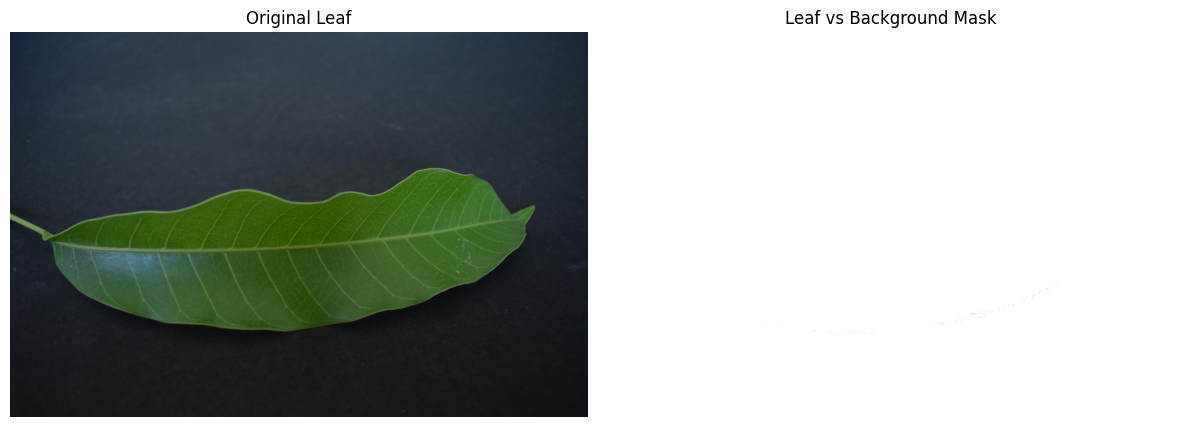

In [ ]:
import cv2
import os
import matplotlib.pyplot as plt

# Select one Mango training image
mango_folder = os.path.join(
    project_dataset_path,
    "train",
    "Mango"
)

image_file = os.listdir(mango_folder)[0]
image_path = os.path.join(mango_folder, image_file)

# Read image
image = cv2.imread(image_path)

# Convert BGR to RGB for displaying
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Convert image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Create a simple mask:
# black background = 0
# leaf = 1
_, mask = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Leaf")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Leaf vs Background Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Check the grayscale pixel-value distribution

print("Minimum grayscale value:", gray.min())
print("Maximum grayscale value:", gray.max())
print("Mean grayscale value:", gray.mean())

# Show some important percentiles
print("\nGrayscale percentiles:")
for p in [1, 5, 10, 25, 50, 75, 90, 95, 99]:
    print(f"{p}%:", np.percentile(gray, p))

Minimum grayscale value: 7
Maximum grayscale value: 173
Mean grayscale value: 50.064198041666664

Grayscale percentiles:
1%: 16.0
5%: 21.0
10%: 24.0
25%: 28.0
50%: 51.0
75%: 64.0
90%: 80.0
95%: 87.0
99%: 108.0


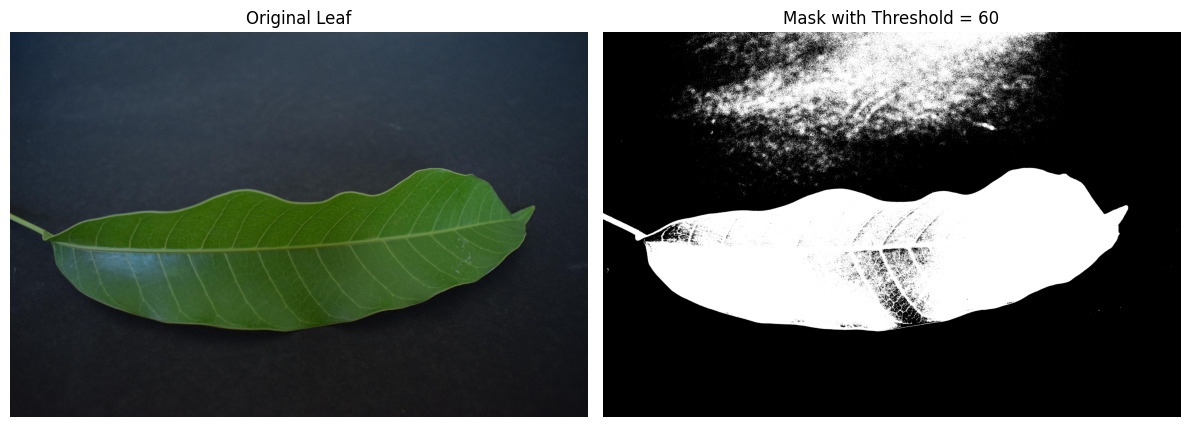

In [ ]:
# Try a higher threshold to separate the leaf from the dark background

threshold_value = 60

_, mask_20 = cv2.threshold(
    gray,
    threshold_value,
    255,
    cv2.THRESH_BINARY
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Leaf")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask_20, cmap="gray")
plt.title("Mask with Threshold = 60")
plt.axis("off")

plt.tight_layout()
plt.show()

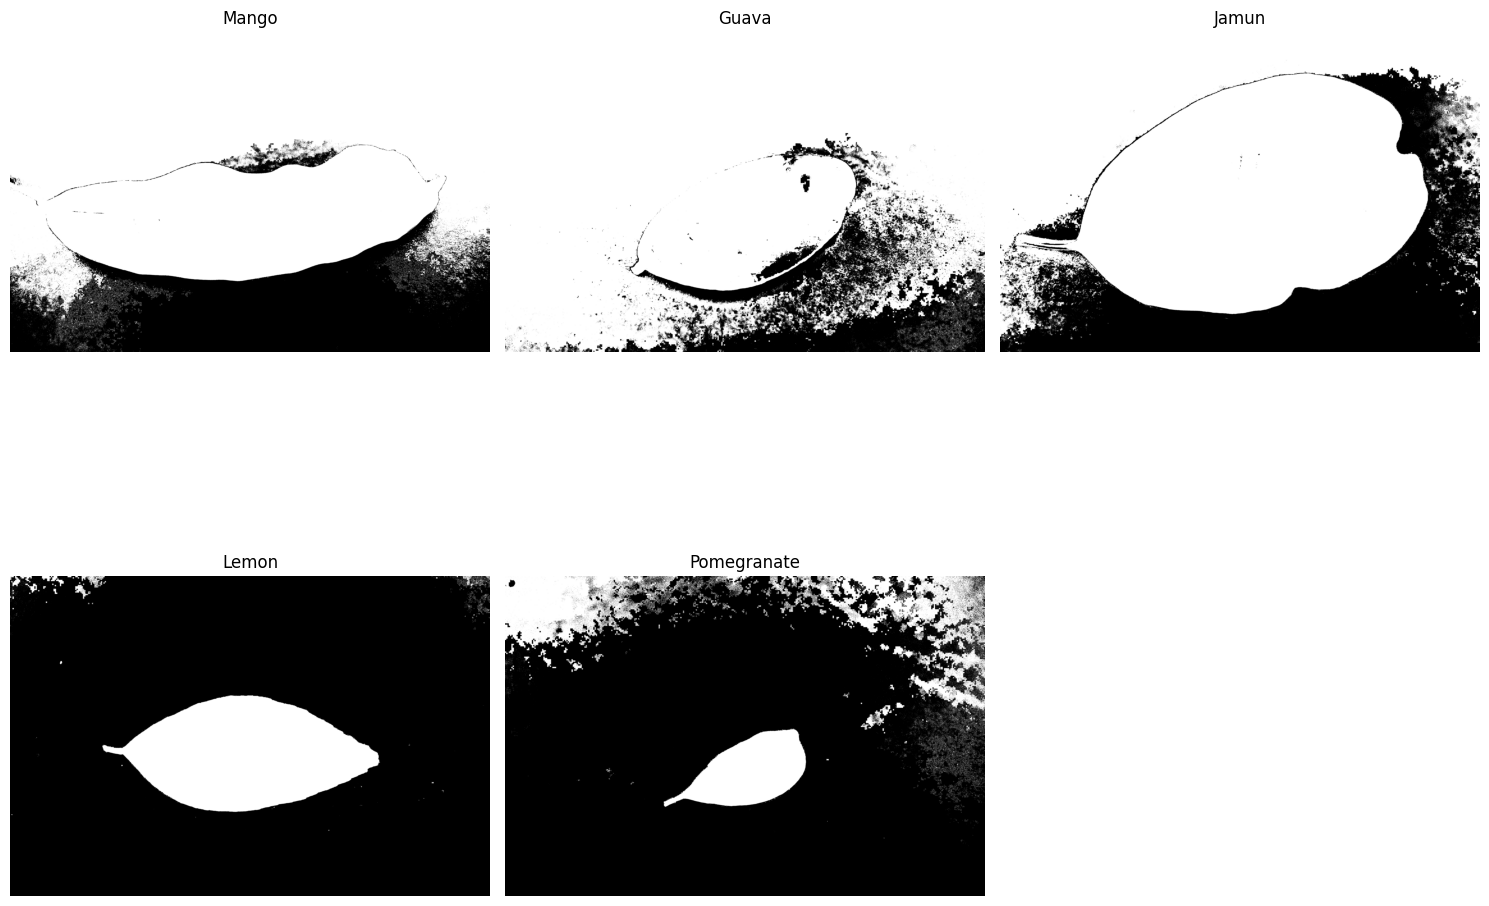

In [ ]:
import cv2
import os
import matplotlib.pyplot as plt

classes = ["Mango", "Guava", "Jamun", "Lemon", "Pomegranate"]

plt.figure(figsize=(15, 12))

for i, class_name in enumerate(classes):

    folder = os.path.join(
        project_dataset_path,
        "train",
        class_name
    )

    # Take the first image from this class
    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    image_path = os.path.join(folder, image_files[0])

    # Read image
    image = cv2.imread(image_path)

    # Convert BGR → RGB
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Convert RGB → HSV
    hsv = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2HSV)

    # Extract HSV channels
    H = hsv[:, :, 0]
    S = hsv[:, :, 1]
    V = hsv[:, :, 2]

    # Create a mask using saturation and brightness
    mask = ((S > 40) & (V > 30)).astype("uint8") * 255

    # Display the mask
    plt.subplot(2, 3, i + 1)
    plt.imshow(mask, cmap="gray")
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

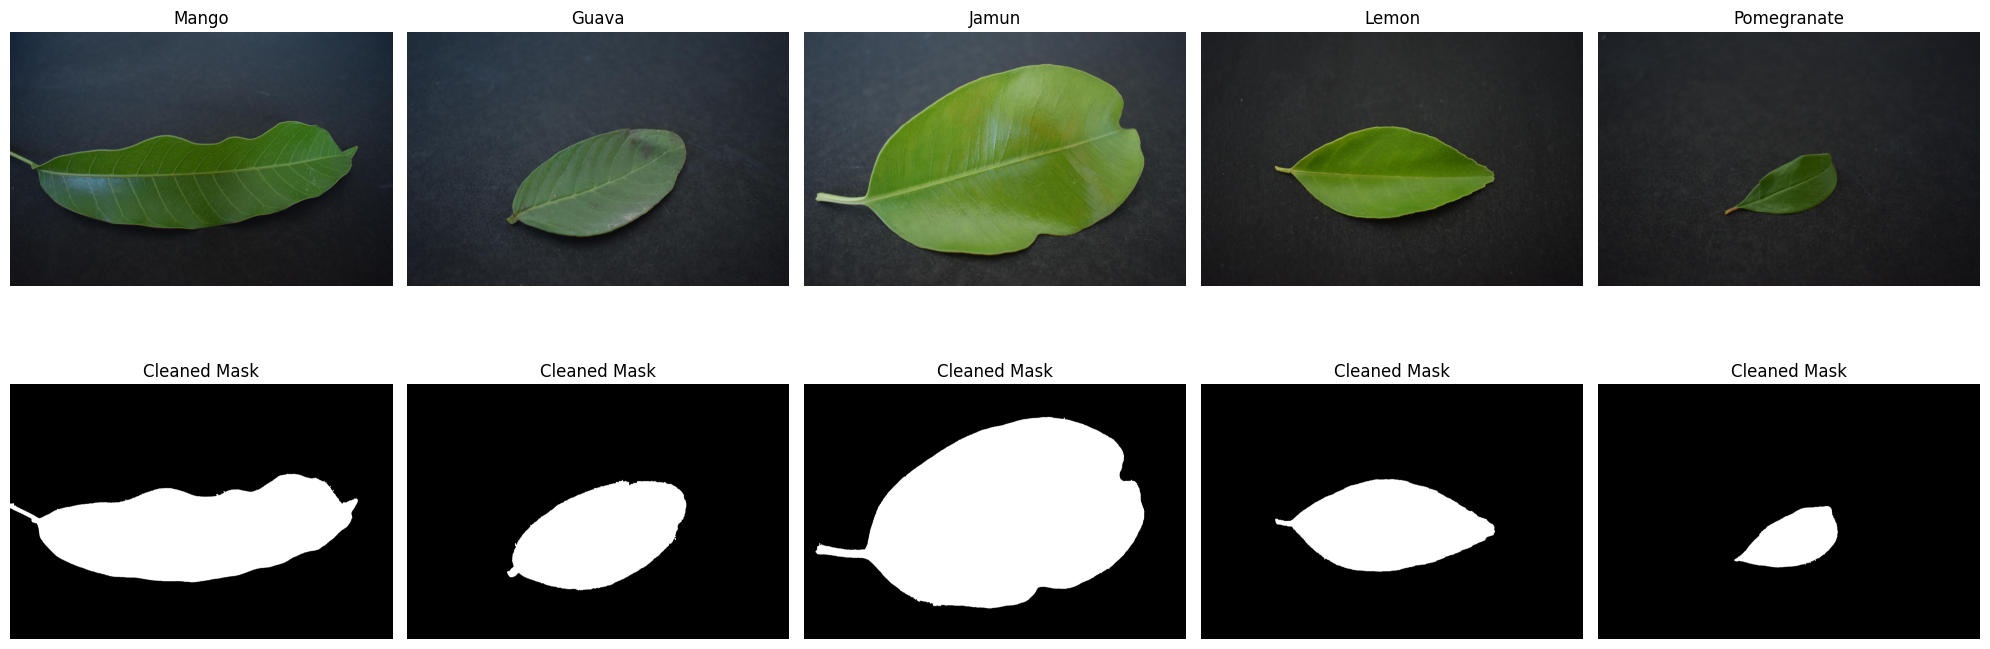

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

def create_leaf_mask(image):

    # Convert image from BGR to HSV
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    # HSV ranges for green leaf detection
    lower_green = np.array([25, 30, 20])
    upper_green = np.array([100, 255, 255])

    # Create initial mask
    mask = cv2.inRange(hsv, lower_green, upper_green)

    # Remove small noise
    kernel = np.ones((7, 7), np.uint8)

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        kernel
    )

    # Fill small gaps inside the leaf
    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        kernel
    )

    # Find contours
    contours, _ = cv2.findContours(
        mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    # Keep the largest detected object
    if contours:

        largest_contour = max(
            contours,
            key=cv2.contourArea
        )

        clean_mask = np.zeros_like(mask)

        cv2.drawContours(
            clean_mask,
            [largest_contour],
            -1,
            255,
            thickness=cv2.FILLED
        )

        return clean_mask

    return mask


# Select one image from each class
classes = [
    "Mango",
    "Guava",
    "Jamun",
    "Lemon",
    "Pomegranate"
]

fig, axes = plt.subplots(2, 5, figsize=(20, 8))

for i, class_name in enumerate(classes):

    folder = os.path.join(
        project_dataset_path,
        "train",
        class_name
    )

    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp")
        )
    ]

    image_path = os.path.join(
        folder,
        image_files[0]
    )

    image = cv2.imread(image_path)

    # Create cleaned mask
    mask = create_leaf_mask(image)

    # Display original image
    axes[0, i].imshow(
        cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    )
    axes[0, i].set_title(class_name)
    axes[0, i].axis("off")

    # Display cleaned mask
    axes[1, i].imshow(
        mask,
        cmap="gray"
    )
    axes[1, i].set_title("Cleaned Mask")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

# **FEATURE EXTRACTION**  ~ DISHANT

In [8]:
import cv2
import numpy as np

def extract_color_features(image, mask):
    """
    Extract color features from the leaf region.

    Parameters:
        image: Original image in BGR format.
        mask: Binary leaf mask where the leaf is white (255)
              and the background is black (0).

    Returns:
        A dictionary containing RGB and HSV color features.
    """

    # Select only the pixels belonging to the leaf
    leaf_pixels_bgr = image[mask > 0]

    # Convert the image from BGR to RGB
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    leaf_pixels_rgb = image_rgb[mask > 0]

    # Convert the image from BGR to HSV
    image_hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    leaf_pixels_hsv = image_hsv[mask > 0]

    # Calculate RGB statistics
    r_mean, g_mean, b_mean = np.mean(leaf_pixels_rgb, axis=0)
    r_std, g_std, b_std = np.std(leaf_pixels_rgb, axis=0)

    # Calculate HSV statistics
    h_mean, s_mean, v_mean = np.mean(leaf_pixels_hsv, axis=0)
    h_std, s_std, v_std = np.std(leaf_pixels_hsv, axis=0)

    # Store the features
    features = {
        "R_mean": r_mean,
        "G_mean": g_mean,
        "B_mean": b_mean,
        "R_std": r_std,
        "G_std": g_std,
        "B_std": b_std,
        "H_mean": h_mean,
        "S_mean": s_mean,
        "V_mean": v_mean,
        "H_std": h_std,
        "S_std": s_std,
        "V_std": v_std
    }

    return features

In [14]:
from google.colab import drive

drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [12]:
# Select one Mango training image

mango_folder = os.path.join(
    "/content/drive/MyDrive/Leaf_Classification/Dataset/images",
    "train",
    "Mango"
)

image_files = [
    f for f in os.listdir(mango_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
]

image_file = image_files[0]
image_path = os.path.join(mango_folder, image_file)

# Read the image
image = cv2.imread(image_path)

# Create the leaf mask using our HSV segmentation function
mask = create_leaf_mask(image)

# Extract color features
color_features = extract_color_features(image, mask)

# Display the extracted features
print("Image:", image_file)
print("\nColor features:")

for feature_name, value in color_features.items():
    print(f"{feature_name}: {value:.2f}")

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Leaf_Classification/Dataset/images/train/Mango'